# 05 · On-board cost (Experiment 2, Figure 2)

Experiment 2 ran the instrument on the Elk Stomp Dev Kit (Elk Audio OS, SUSHI, the plugin in `plugin/`, 64-sample
callback at 48 kHz) with Elk's demo loop as input, for three corpora: a 103 s field recording (1,107 grains), the
percussive corpus (5,115) and the field-recordings corpus (12,018), each with the corpus latent table in 32-bit
floats and in 8 bits: six runs of 210–330 s. Each run used `sushi --timing-statistics` (the callback share of every
processor) and the plugin's per-stage timers, and printed its logs over the serial console.

The transcripts are in `results/board/raw/` (the commands sent in `results/board/cmds/`), exactly as captured. The
board has no real-time clock, so its dates read 2025-05-29 and runs are addressed by the board's stamp.
`analysis/board_logs.py` parses them. This notebook computes every on-board number the paper prints and redraws
Figure 2.

In [1]:
import json

import numpy as np

from analysis import demo, report
from analysis.board_logs import load_runs, parse_bench
import importlib.util, sys
spec = importlib.util.spec_from_file_location("fig_budget", demo.REPO / "figures/fig_budget.py")
fig_budget = importlib.util.module_from_spec(spec); spec.loader.exec_module(fig_budget)

runs = load_runs()
for r in runs:
    print(f"{r.transcript:20s} stamp {r.stamp}  {r.grains:>6,} grains  {r.table:4s} table {r.header['table_bytes']:>9,} B  "
          f"run {r.run_seconds} s  student={r.header['student']} mode={r.header['mode']}")

R1-gonza-f32.txt     stamp 20250529-233122   1,107 grains  f32  table   283,392 B  run 330 s  student=1 mode=elkasync
R1-gonza-int8.txt    stamp 20250529-234819   1,107 grains  int8 table    75,276 B  run 210 s  student=1 mode=elkasync
R1b-perc-f32.txt     stamp 20250529-185624   5,115 grains  f32  table 1,309,440 B  run 330 s  student=1 mode=elkasync
R1b-perc-int8.txt    stamp 20250529-190203   5,115 grains  int8 table   347,820 B  run 210 s  student=1 mode=elkasync
R1-field-f32.txt     stamp 20250529-234240  12,018 grains  f32  table 3,076,608 B  run 330 s  student=1 mode=elkasync
R1-field-int8.txt    stamp 20250529-235538  12,018 grains  int8 table   817,224 B  run 210 s  student=1 mode=elkasync


## 1. Every run

Per analysis (every 4,480 samples): `fe` front-end (resampling to 44.1 kHz, one 4096-point FFT, 80 mel bands and the
spectral descriptors), `st` student (RTNeural), `se` search (similarities to every grain, penalties, softmax), `wk`
the whole analysis on the worker thread. Medians (p50) and 99th percentiles in ms. The callback share is SUSHI's
measurement for the plugin, in % of the 1,333 µs callback.

In [2]:
rows = []
for r in runs:
    s, u, cb = r.stages, r.summary, r.callback["granular"]
    rows.append({"grains": r.grains, "table": r.table, "hops": u["hops"], "p50": u["p50"], "p99": u["p99"], "max": u["max"],
                 "lost": u["ring_overruns"] + u["ring_stalls"] + u["cmd_drops"] + u["async_req_failed"],
                 "cb": f"{cb[0]:.2f} / {cb[2]:.2f}", "fe": s["fe_p50"], "st": s["st_p50"], "se": s["se_p50"], "wk": s["wk_p50"],
                 "wk99": s["wk_p99"], "isw": "/".join(map(str, r.isw))})
report.table(rows, [("grains", "Grains", ","), ("table", "Table"), ("hops", "Analyses", ","), ("p50", "Period p50 (ms)", ".3f"),
                    ("p99", "p99", ".3f"), ("max", "max", ".1f"), ("lost", "Lost input or analyses"),
                    ("cb", "Callback avg / max (%)"), ("fe", "fe", ".3f"), ("st", "st", ".3f"), ("se", "se", ".3f"),
                    ("wk", "wk p50", ".3f"), ("wk99", "wk p99", ".3f"), ("isw", "EVL in-band switches")])

| Grains | Table | Analyses | Period p50 (ms) | p99 | max | Lost input or analyses | Callback avg / max (%) | fe | st | se | wk p50 | wk p99 | EVL in-band switches |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 1,107 | f32 | 3,485 | 93.325 | 94.774 | 133.4 | 0 | 2.09 / 10.10 | 3.963 | 0.960 | 1.292 | 6.126 | 8.084 | 0/0 |
| 1,107 | int8 | 2,205 | 93.327 | 94.837 | 125.6 | 0 | 1.95 / 10.92 | 3.982 | 0.908 | 0.419 | 5.378 | 9.197 | 0/0 |
| 5,115 | f32 | 3,477 | 93.373 | 94.920 | 137.6 | 0 | 2.22 / 10.70 | 3.946 | 0.957 | 5.536 | 10.321 | 13.650 | 0/0 |
| 5,115 | int8 | 2,194 | 93.353 | 94.907 | 130.7 | 0 | 2.08 / 8.87 | 3.958 | 0.930 | 2.141 | 6.935 | 9.536 | 0/0 |
| 12,018 | f32 | 3,477 | 93.324 | 94.945 | 126.6 | 0 | 2.39 / 9.17 | 3.961 | 0.909 | 12.726 | 17.550 | 24.522 | 0/0 |
| 12,018 | int8 | 2,188 | 93.304 | 94.949 | 127.1 | 0 | 2.15 / 10.00 | 3.929 | 0.960 | 4.791 | 9.574 | 12.572 | 0/0 |

## 2. No lost input, no dropped analysis, and the analysis period

`ring_overruns` counts input samples the audio callback could not hand to the worker, `ring_stalls` analyses whose
input was lost, `cmd_drops` grain commands the callback could not take, `async_req_failed` analysis requests SUSHI
refused. `async_done` is the number of analyses completed (one more than `hops` when a request was in flight at the
stop). The period is the interval between analyses, and its target is 4,480 samples at 48 kHz.

In [3]:
lost = {r.transcript: {k: r.summary[k] for k in ("ring_overruns", "ring_stalls", "cmd_drops", "async_req_failed")} for r in runs}
no_loss = all(v == 0 for d in lost.values() for v in d.values())
done_ok = all(r.summary["async_done"] - r.summary["hops"] in (0, 1) for r in runs)
period = runs[0].period_ms
p50s = [r.summary["p50"] for r in runs]
isw0 = all(v == 0 for r in runs for v in r.isw)
print(f"all loss counters zero: {no_loss} | every requested analysis completed: {done_ok} | EVL in-band switches all zero: {isw0}")
print(f"analysis period: {runs[0].header['hop']} samples / {runs[0].header['sr']} Hz = {period:.3f} ms, "
      f"measured medians {min(p50s):.3f}–{max(p50s):.3f} ms")

all loss counters zero: True | every requested analysis completed: True | EVL in-band switches all zero: True
analysis period: 4480 samples / 48000 Hz = 93.333 ms, measured medians 93.304–93.373 ms


## 3. The audio callback is not the limit

SUSHI's `--timing-statistics` report (in each transcript) gives the plugin's share of the 64-sample callback
(100 % = 1,333.33 µs): average, minimum and maximum over the run. The audio callback only mixes scheduled grains, and the
analysis runs on the worker thread.

In [4]:
avg = [r.callback["granular"][0] for r in runs]
mx = [r.callback["granular"][2] for r in runs]
print(f"plugin average share of the callback: {min(avg):.2f}–{max(avg):.2f} %  (runs: {', '.join(f'{a:.3f}' for a in avg)})")
print(f"largest single callback: {max(mx):.2f} %  (run {runs[int(np.argmax(mx))].stamp}, {runs[int(np.argmax(mx))].grains:,} grains, {runs[int(np.argmax(mx))].table})")
print("engine total (all processors) average:", ", ".join(f"{r.callback['Engine total'][0]:.2f}" for r in runs), "%")

plugin average share of the callback: 1.95–2.39 %  (runs: 2.094, 1.949, 2.222, 2.082, 2.391, 2.149)
largest single callback: 10.92 %  (run 20250529-234819, 1,107 grains, int8)
engine total (all processors) average: 4.03, 3.88, 4.27, 4.05, 4.60, 4.13 %


The paper compares this with 0.093 % for the same plugin on an M1 Max laptop (a 30 s `sushi --timing-statistics`
run at 64 samples, 48 kHz). That timings file was not archived. The value is from the author's notes of 25 Aug 2026
and **cannot be reproduced from the data in this repository**.

## 4. What the analysis costs, stage by stage (Figure 2)

| Grains | front-end p50 (ms) | student | search, 32-bit | search, 8-bit | 8-bit speed-up | stack, 32-bit | stack, 8-bit | largest stage, 32-bit |
|---|---|---|---|---|---|---|---|---|
| 1,107 | 3.963 | 0.960 | 1.292 | 0.419 | 3.08 | 6.2 | 5.3 | front-end |
| 5,115 | 3.946 | 0.957 | 5.536 | 2.141 | 2.59 | 10.4 | 7.0 | search |
| 12,018 | 3.961 | 0.909 | 12.726 | 4.791 | 2.66 | 17.6 | 9.7 | search |

front-end 3.929–3.982 ms and student 0.908–0.960 ms in all six runs (= 0.97–1.03 % of the 93.3 ms period)
search: 1.047 ms per 1,000 grains with the 32-bit table, 0.399 with the 8-bit table (least squares)


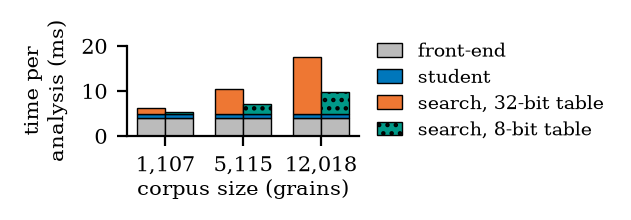

In [5]:
stage_rows = fig_budget.stage_rows(runs)
per = []
for r in stage_rows:
    per.append({"grains": r["grains"], "fe": r["fe32"], "st": r["st32"], "se32": r["m32"], "se8": r["m8"],
                "speed": r["m32"] / r["m8"], "tot32": r["fe32"] + r["st32"] + r["m32"], "tot8": r["fe32"] + r["st32"] + r["m8"],
                "largest32": max((("front-end", r["fe32"]), ("student", r["st32"]), ("search", r["m32"])), key=lambda x: x[1])[0]})
report.table(per, [("grains", "Grains", ","), ("fe", "front-end p50 (ms)", ".3f"), ("st", "student", ".3f"),
                   ("se32", "search, 32-bit", ".3f"), ("se8", "search, 8-bit", ".3f"), ("speed", "8-bit speed-up", ".2f"),
                   ("tot32", "stack, 32-bit", ".1f"), ("tot8", "stack, 8-bit", ".1f"), ("largest32", "largest stage, 32-bit")])
st_all = [r.stages["st_p50"] for r in runs]
fe_all = [r.stages["fe_p50"] for r in runs]
g = np.array([r["grains"] for r in stage_rows], float)
slope32 = np.polyfit(g / 1000, [r["m32"] for r in stage_rows], 1)[0]
slope8 = np.polyfit(g / 1000, [r["m8"] for r in stage_rows], 1)[0]
print(f"front-end {min(fe_all):.3f}–{max(fe_all):.3f} ms and student {min(st_all):.3f}–{max(st_all):.3f} ms in all six runs "
      f"(= {100 * min(st_all) / period:.2f}–{100 * max(st_all) / period:.2f} % of the {period:.1f} ms period)")
print(f"search: {slope32:.3f} ms per 1,000 grains with the 32-bit table, {slope8:.3f} with the 8-bit table (least squares)")
fig = fig_budget.draw(stage_rows, out_base=str(demo.REPO / "figures" / "fig_budget"))

The figure is drawn from the transcripts, and `results/board/budget.json` holds the medians that were copied by hand into
the paper's figure script. They agree:

In [6]:
bj = json.loads((demo.REPO / "results/board/budget.json").read_text())
same = True
for c, r in zip(bj["corpora"], stage_rows):
    m = c["measured"]
    pair = [(m["frontend_ms"], r["fe32"]), (m["student_ms"], r["st32"]), (m["match_f32_ms"], r["m32"]), (m["match_int8_ms"], r["m8"])]
    same &= all(abs(a - b) < 1e-9 for a, b in pair) and c["grains"] == r["grains"]
    print(f"{c['grains']:>6,} grains  budget.json {[a for a, _ in pair]}  transcripts {[b for _, b in pair]}")
print("budget.json = transcripts:", same, f"| fitted slopes in budget.json: {bj['stages']['match_f32_ms_per_1000_grains']['value']}, "
      f"{bj['stages']['match_int8_ms_per_1000_grains']['value']} ms per 1,000 grains")

 1,107 grains  budget.json [3.963, 0.96, 1.292, 0.419]  transcripts [3.963, 0.96, 1.292, 0.419]
 5,115 grains  budget.json [3.946, 0.957, 5.536, 2.141]  transcripts [3.946, 0.957, 5.536, 2.141]
12,018 grains  budget.json [3.961, 0.909, 12.726, 4.791]  transcripts [3.961, 0.909, 12.726, 4.791]
budget.json = transcripts: True | fitted slopes in budget.json: 1.047, 0.399 ms per 1,000 grains


## 5. Shorter analysis periods

How much of one core would the worker need at a shorter period? Holding the measured cost per analysis constant gives
an upper bound (the resampling part shrinks with the period, so the true cost is lower). The paper states the
conclusion only: for large corpora the search bounds the shortest analysis period.

In [7]:
out = []
for r in runs:
    for per_ms in (93.3, 46.7, 23.3):
        out.append({"grains": r.grains, "table": r.table, "period": per_ms, "load": 100 * r.stages["wk_p50"] / per_ms,
                    "search": 100 * r.stages["se_p50"] / r.stages["wk_p50"]})
report.table([o for o in out if o["grains"] in (1107, 12018)],
             [("grains", "Grains", ","), ("table", "Table"), ("period", "Period (ms)", ".1f"),
              ("load", "worker load, % of one core (upper bound)", ".0f"), ("search", "search share of the analysis (%)", ".0f")])

| Grains | Table | Period (ms) | worker load, % of one core (upper bound) | search share of the analysis (%) |
|---|---|---|---|---|
| 1,107 | f32 | 93.3 | 7 | 21 |
| 1,107 | f32 | 46.7 | 13 | 21 |
| 1,107 | f32 | 23.3 | 26 | 21 |
| 1,107 | int8 | 93.3 | 6 | 8 |
| 1,107 | int8 | 46.7 | 12 | 8 |
| 1,107 | int8 | 23.3 | 23 | 8 |
| 12,018 | f32 | 93.3 | 19 | 73 |
| 12,018 | f32 | 46.7 | 38 | 73 |
| 12,018 | f32 | 23.3 | 75 | 73 |
| 12,018 | int8 | 93.3 | 10 | 50 |
| 12,018 | int8 | 46.7 | 21 | 50 |
| 12,018 | int8 | 23.3 | 41 | 50 |

## 6. Microbenchmarks in isolation

`elkgrain_bench` (built from `plugin/src/BenchMain.cpp`, pinned to one core with `taskset`) times the student and the
search alone (`results/board/raw/S6b-bench.txt`).

In [8]:
bench = parse_bench()
report.table(bench, [("kind", "Benchmark"), ("cpu", "Core"), ("table", "Table"), ("grains", "Grains"),
                     ("p50_us", "p50 (µs)", ".1f"), ("p99_us", "p99 (µs)", ".1f"), ("mmac_s", "M MAC/s"),
                     ("ms_per_1000_grains", "ms per 1,000 grains")])

| Benchmark | Core | Table | Grains | p50 (µs) | p99 (µs) | M MAC/s | ms per 1,000 grains |
|---|---|---|---|---|---|---|---|
| student | 1 | — | — | 812.5 | 945.3 | 126.0 | — |
| student | 0 | — | — | 811.6 | 949.4 | 126.2 | — |
| match | 1 | f32 | 12018 | 12497.2 | 12686.1 | — | 1.0399 |
| match | 1 | int8 | 12018 | 4453.8 | 4638.9 | — | 0.3706 |

## Numbers of the paper this notebook reproduces

In [9]:
by = {(r.grains, r.table): r for r in runs}
f32 = {r["grains"]: r for r in stage_rows}
speed = [r["m32"] / r["m8"] for r in stage_rows]
ok = report.checks([
    ("Section 3: analysis every 4,480 samples", "4,480 samples = 93.3 ms", f"{runs[0].header['hop']:,} samples = {period:.1f} ms",
     runs[0].header["hop"] == 4480 and f"{period:.1f}" == "93.3"),
    ("Section 4: corpora on the board", "1,107 / 5,115 / 12,018 grains", " / ".join(f"{r['grains']:,}" for r in stage_rows),
     [r["grains"] for r in stage_rows] == [1107, 5115, 12018]),
    ("Section 4: a 103 s field recording (1,107 grains)", "103 s", "1,107 grains of ≈93 ms, the pack (102.9 s) is not shipped", None),
    ("Results: no run lost input or dropped an analysis", "none", f"loss counters all 0: {no_loss}, all analyses done: {done_ok}", no_loss and done_ok),
    ("Results: callback share, average", "1.95–2.39 %", f"{min(avg):.2f}–{max(avg):.2f} %", (f"{min(avg):.2f}", f"{max(avg):.2f}") == ("1.95", "2.39")),
    ("Results: single callbacks up to", "10.9 %", f"{max(mx):.1f} %", f"{max(mx):.1f}" == "10.9"),
    ("Results: laptop callback share", "0.093 %", "not in the shipped logs (author's notes of 25 Aug)", None),
    ("abstract, Results: student ≈ 1 % of the period", "about 1 %", f"{100 * min(st_all) / period:.2f}–{100 * max(st_all) / period:.2f} %",
     round(100 * max(st_all) / period) == 1 and round(100 * min(st_all) / period) == 1),
    ("abstract: only the search grows with corpus size", "front-end and student flat",
     f"fe {min(fe_all):.2f}–{max(fe_all):.2f} ms, st {min(st_all):.2f}–{max(st_all):.2f} ms, search {f32[1107]['m32']:.2f} to {f32[12018]['m32']:.2f} ms",
     max(fe_all) - min(fe_all) < 0.1 and max(st_all) - min(st_all) < 0.1 and f32[12018]["m32"] > 9 * f32[1107]["m32"]),
    ("Results: search the largest cost from 5,115 grains on (32-bit)", "yes",
     ", ".join(f"{r['grains']:,}: {'search' if r['m32'] > max(r['fe32'], r['st32']) else 'front-end'}" for r in stage_rows),
     [r["m32"] > max(r["fe32"], r["st32"]) for r in stage_rows] == [False, True, True]),
    ("Results: 8-bit table cut the largest search to", "4.79 ms", f"{f32[12018]['m8']:.2f} ms", f"{f32[12018]['m8']:.2f}" == "4.79"),
    ("Figure 2: 8-bit search faster by", "2.6 to 3.1 times", f"{min(speed):.2f} to {max(speed):.2f}",
     (f"{min(speed):.1f}", f"{max(speed):.1f}") == ("2.6", "3.1")),
    ("Figure 2: every bar", "measured medians", f"= budget.json: {same}", same),
])
print("all equal:", ok)

| Paper element | Printed in the paper | Computed here | Equal |
|---|---|---|---|
| Section 3: analysis every 4,480 samples | 4,480 samples = 93.3 ms | 4,480 samples = 93.3 ms | ✓ |
| Section 4: corpora on the board | 1,107 / 5,115 / 12,018 grains | 1,107 / 5,115 / 12,018 | ✓ |
| Section 4: a 103 s field recording (1,107 grains) | 103 s | 1,107 grains of ≈93 ms, the pack (102.9 s) is not shipped | n/a |
| Results: no run lost input or dropped an analysis | none | loss counters all 0: True, all analyses done: True | ✓ |
| Results: callback share, average | 1.95–2.39 % | 1.95–2.39 % | ✓ |
| Results: single callbacks up to | 10.9 % | 10.9 % | ✓ |
| Results: laptop callback share | 0.093 % | not in the shipped logs (author's notes of 25 Aug) | n/a |
| abstract, Results: student ≈ 1 % of the period | about 1 % | 0.97–1.03 % | ✓ |
| abstract: only the search grows with corpus size | front-end and student flat | fe 3.93–3.98 ms, st 0.91–0.96 ms, search 1.29 to 12.73 ms | ✓ |
| Results: search the largest cost from 5,115 grains on (32-bit) | yes | 1,107: front-end, 5,115: search, 12,018: search | ✓ |
| Results: 8-bit table cut the largest search to | 4.79 ms | 4.79 ms | ✓ |
| Figure 2: 8-bit search faster by | 2.6 to 3.1 times | 2.59 to 3.08 | ✓ |
| Figure 2: every bar | measured medians | = budget.json: True | ✓ |

all equal: True
